# Observation/action features associated with rewards

This notebook screens features against **closeToOverflow**, **economic**, **distance**, and the main **AlarmReward**. It loads notebook 01's compressed datasets without starting Grid2Op.

**Alignment:** pre-decision observation `s[t]` and requested action `a[t]` are compared with the reward returned by their transition, `r[t]`. Post-transition observation `s[t+1]` is included only as an explanatory diagnostic.

**Statistics:** Pearson measures linear association, Spearman measures monotonic association (rank correlation). Binary-action Pearson correlations are point-biserial correlations. We compute correlations within each agent/episode before averaging, so long episodes and differences between policies do not dominate. Constant signals have **undefined correlation**, never zero. Autocorrelated steps are not independent samples; no timestep-level p-values are reported.

**Feature selection:** reserve entire chronics for validation, rank on training chronics, and inspect held-out correlations. With only ten chronics this is exploratory screening. Correlation does not establish an action's causal effect: intervention is triggered by grid conditions. The alarm reward is sparse and analyzed separately at episode level.

In [1]:
from pathlib import Path
import gzip
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "agent.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "agent.py").exists(), "Run from the repository or notebooks directory."
DATA_DIR = ROOT / "data" / "irl_datasets"
OUTPUT_DIR = ROOT / "artifacts" / "reward_correlations"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
AGENTS = ["normal", "no_revert", "no_action"]
DENSE_REWARDS = ["closeToOverflow", "economic", "distance"]
ARCHIVES = {agent: DATA_DIR / f"{agent}.jsonl.gz" for agent in AGENTS}
for path in ARCHIVES.values():
    if not path.exists():
        raise FileNotFoundError(f"First save the datasets using notebook 01: {path}")

# Add individual equipment variables only after inspecting aggregate features.
# Example: {"rho": [0, 12], "gen_p": [0]}; indices require matching equipment IDs.
ELEMENT_FEATURES = {}
REBUILD_FEATURES = False
SPLIT_SEED = 42
MIN_STEPS = 30             # minimum finite samples for one within-episode correlation
MIN_EPISODES = 3           # minimum informative training episodes per agent
MIN_ABS_CORRELATION = 0.20 # exploratory, not a statistical significance threshold
TOP_N = 12
plt.rcParams.update({"figure.figsize": (11, 4), 
                     "axes.spines.top": False, 
                     "axes.spines.right": False, 
                     "axes.grid": True,
                     "grid.alpha": 0.3,
                     "grid.linestyle": '--'})

def show_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 1. Explicit, inspectable feature definitions

Electrical features are summaries of the full equipment arrays. Counts preserve categorical meanings: bus numbers are not treated as continuous numbers. We omit absolute calendar year, identifiers, terminal-scoring flags, empty storage/alert fields and inactive shunts from candidate policy inputs. Hour/day-of-week are encoded cyclically.

`bus_not1_count` matches the all-bus-1 reference used by `DistanceReward`, not necessarily a physical reference topology. Loading and dispatch summaries can correlate with other reward formulas without being their exact inputs. `economic` also uses generator cost metadata, absent from these observations.

Action features describe **requests**, including zero/no-op and combined controls. `bus_changes` counts assignments differing from the current bus, while `bus_commands` counts explicit assignments even if redundant. Illegal-action flags are outcomes, not pre-decision features.

In [12]:
# FEATURE_EXTRACTION: changes to this cell invalidate the feature cache.
def vector(data, field):
    """Convert an observation/action array to a numeric vector."""
    return np.asarray(data.get(field, []), dtype=float).reshape(-1)


def first(data, field, default=np.nan):
    values = vector(data, field)
    return float(values[0]) if values.size else default


def valid_grid_state(obs):
    if obs is None:
        return False
    rho = vector(obs, "rho")
    status = vector(obs, "line_status")
    topology = vector(obs, "topo_vect")
    terminal_like = status.size and not status.any() and topology.size and (topology == -1).all()
    return bool(rho.size and np.isfinite(rho).all() and not terminal_like)


def observation_features(obs):
    """Compact pre-decision features; same definitions can diagnose post-states."""
    if not valid_grid_state(obs):
        return {}  # missing, never a fictitious zero-loading healthy state
    result = {}
    rho = vector(obs, "rho")
    
    result.update(rho_max=rho.max(), 
                  rho_mean=rho.mean(), 
                  rho_std=rho.std(),
                  rho_p95=np.quantile(rho, .95), 
                  overloaded_count=(rho > 1).sum(),
                  near_overload_count=(rho >= .95).sum(),
                  overload_excess=np.maximum(rho - 1, 0).sum())
    
    topology = vector(obs, "topo_vect")
    result.update(disconnected_lines=(vector(obs, "line_status") == 0).sum(),
                  bus2_count=(topology == 2).sum(), bus_not1_count=(topology != 1).sum())
    
    for field in ["gen_p", "gen_q", "load_p", "load_q"]:
        values = vector(obs, field)
        if values.size:
            result[field + "_sum"] = values.sum()
            result[field + "_std"] = values.std()
    
    for field in ["gen_v", "load_v", "v_or", "v_ex"]:
        values = vector(obs, field)
        if values.size:
            result[field + "_min"] = values.min()
            result[field + "_mean"] = values.mean()
    
    for field in ["p_or", "q_or", "p_ex", "q_ex", "a_or", "a_ex"]:
        values = np.abs(vector(obs, field))
        if values.size:
            result[field + "_abs_mean"] = values.mean()
            result[field + "_abs_max"] = values.max()
    
    for field in ["target_dispatch", "actual_dispatch", "curtailment"]:
        values = vector(obs, field)
        result[field + "_abs_sum"] = np.abs(values).sum()
    
    for field in ["gen_margin_up", "gen_margin_down", "gen_p_before_curtail"]:
        values = vector(obs, field)
        if values.size:
            result[field + "_sum"] = values.sum()
    
    for field in ["time_before_cooldown_line", "time_before_cooldown_sub", "timestep_overflow"]:
        values = vector(obs, field)
        result[field + "_positive_count"] = (values > 0).sum()
        result[field + "_max"] = values.max() if values.size else np.nan
    
    maintenance = vector(obs, "time_next_maintenance")
    result["maintenance_active_count"] = (maintenance == 0).sum()
    result["maintenance_scheduled_count"] = (maintenance >= 0).sum()
    result["attention_budget"] = first(obs, "attention_budget")
    
    alarm_age = first(obs, "time_since_last_alarm")
    result["has_previous_alarm"] = float(alarm_age >= 0)
    
    # The sentinel -1 means never, not a negative elapsed duration.
    result["steps_since_alarm"] = alarm_age if alarm_age >= 0 else np.nan
    hour = first(obs, "hour_of_day") + first(obs, "minute_of_hour") / 60
    weekday = first(obs, "day_of_week")
    
    for label, phase in [("hour", hour / 24), ("weekday", weekday / 7)]:
        result[label + "_sin"] = np.sin(2 * np.pi * phase)
        result[label + "_cos"] = np.cos(2 * np.pi * phase)
    
    for field, indices in ELEMENT_FEATURES.items():
        values = vector(obs, field)
        for index in indices:
            if index >= len(values) or index < 0:
                raise ValueError(f"Invalid equipment index: {field}[{index}]")
            result[f"{field}[{index}]"] = values[index]
    return result


def action_features(action, obs):
    """Explicit action components from the portable archives created by notebook 01."""
    bus = vector(action, "set_bus")
    topology = vector(obs, "topo_vect")
    status = vector(action, "set_line_status")
    redisp = vector(action, "redispatch")
    curtail = vector(action, "curtail")
    
    result = dict(
        bus_commands=(bus != 0).sum(),
        bus_changes=((bus != 0) & (bus != topology)).sum() if bus.size == topology.size else np.nan,
        bus1_commands=(bus == 1).sum(), bus2_commands=(bus == 2).sum(),
        disconnect_terminal_commands=(bus == -1).sum(),
        bus_toggle_count=(vector(action, "change_bus") != 0).sum(),
        reconnect_count=(status == 1).sum(), disconnect_count=(status == -1).sum(),
        line_toggle_count=(vector(action, "change_line_status") != 0).sum(),
        redispatch_abs_mw=np.abs(redisp).sum(), redispatch_signed_mw=redisp.sum(),
        curtail_commands=(curtail >= 0).sum(),
        curtail_cap_reduction=np.sum(1 - curtail[curtail >= 0]),
        alarm_area_count=(vector(action, "raise_alarm") != 0).sum(),
        storage_abs_mw=np.abs(vector(action, "storage_power")).sum(),
    )
    
    result["has_topology"] = int(result["bus_commands"] + result["bus_toggle_count"] > 0)
    result["has_line_switch"] = int(result["reconnect_count"] + result["disconnect_count"] + result["line_toggle_count"] > 0)
    result["combined_topology_line"] = result["has_topology"] * result["has_line_switch"]
    result["intervention"] = int(any(result[k] > 0 for k in ["has_topology", "has_line_switch",
        "redispatch_abs_mw", "curtail_commands", "alarm_area_count", "storage_abs_mw"]))
    return result

## 2. Read one episode at a time and cache the small feature table

The raw archives exceed 1 GB compressed. Streaming avoids loading all three datasets together. First execution can take several minutes; progress is printed per episode. Later runs reuse the CSV cache if source file sizes/timestamps and extraction code match.

Current-state features use `obs__`, requested actions use `act__`, and next-state diagnostic features use `post__`. Missing final observations in legacy archives remain missing. Alarm reward is initially named `main`: confirm its identity from metadata/configuration below before interpreting it as AlarmReward.

In [3]:
# FEATURE_EXTRACTION: transition alignment and reward decoding.
def decode_archive_object(value):
    if set(value) == {"__nonfinite__"}:
        return float(value["__nonfinite__"])
    return value


def episode_rows(agent, episode_id, episode):
    observations = episode["observations"]
    n = len(episode["actions"])
    
    assert all(len(episode[k]) == n for k in ["observations", "rewards", "infos"])
    
    if "next_observations" in episode:
        assert len(episode["next_observations"]) == n
    if "dones" in episode:
        assert len(episode["dones"]) == n
    
    for t in range(n):
        obs, action, info = observations[t], episode["actions"][t], episode["infos"][t]
        if "next_observations" in episode:
            nxt = episode["next_observations"][t]
        else:
            nxt = observations[t + 1] if t + 1 < n else episode.get("final_observation")
    
        flagged = any(bool(info.get(k, False)) for k in
                      ["is_illegal", "is_ambiguous", "failed_redispatching", "is_illegal_reco"])
        
        row = dict(agent=agent, episode_id=str(episode_id), chronic=episode["chronic"],
                   env_seed=episode.get("env_seed"), t=t, episode_length=n,
                   is_last=t == n - 1, done_recorded=bool(episode["dones"][t]) if "dones" in episode else False,
                   terminal_flag_available="dones" in episode, flagged=flagged,
                   valid_pre=valid_grid_state(obs), valid_post=valid_grid_state(nxt),
                   reward_main=float(episode["rewards"][t]))
        row.update({"reward_" + k: float(info.get("rewards", {}).get(k, np.nan)) for k in DENSE_REWARDS})
        row.update({"obs__" + k: v for k, v in observation_features(obs).items()})
        row.update({"act__" + k: v for k, v in action_features(action, obs).items()})
        row.update({"post__" + k: v for k, v in observation_features(nxt).items()})
        yield row


# Include extraction cell text in the fingerprint so edits cannot silently reuse stale features.
notebook = json.loads((ROOT / "notebooks" / "02_reward_correlations.ipynb").read_text())
extraction_code = "\n".join("".join(c["source"]) for c in notebook["cells"] 
                            if c["cell_type"] == "code" and "# FEATURE_EXTRACTION" in "".join(c["source"]))
fingerprint = dict(files={a: [p.stat().st_size, p.stat().st_mtime_ns] for a, p in ARCHIVES.items()},
                   code=hashlib.sha256(extraction_code.encode()).hexdigest(), elements=ELEMENT_FEATURES)
cache_path = OUTPUT_DIR / "transition_features.csv.gz"
manifest_path = OUTPUT_DIR / "feature_manifest.json"
cache_valid = (cache_path.exists() and manifest_path.exists() and
               json.loads(manifest_path.read_text())["fingerprint"] == fingerprint)

if cache_valid and not REBUILD_FEATURES:
    features = pd.read_csv(cache_path, dtype={"episode_id": str})
    archive_metadata = json.loads(manifest_path.read_text())["metadata"]
    print("Loaded cached features:", features.shape)
else:
    frames, archive_metadata = [], {}
    for agent, path in ARCHIVES.items():
        with gzip.open(path, "rt", encoding="utf-8") as stream:
            header = json.loads(next(stream))
            
            if header.get("schema_version") != 1:
                raise ValueError("Unsupported archive schema")
            
            archive_metadata[agent] = header.get("metadata", {})
            seen = set()
            
            for line in stream:
                item = json.loads(line, object_hook=decode_archive_object)
                episode_id = str(item["episode_id"])
                
                if episode_id in seen:
                    raise ValueError("Duplicate episode ID")
                
                seen.add(episode_id)
                frame = pd.DataFrame(episode_rows(agent, episode_id, item["episode"]))
                frames.append(frame)
                
                print(agent, episode_id, item["episode"]["chronic"], len(frame), "transitions", flush=True)
                del item, line
            
            assert len(seen) == header["episodes"], "Incomplete archive"
    
    features = pd.concat(frames, ignore_index=True)
    del frames

    features.to_csv(cache_path, index=False)
    manifest_path.write_text(json.dumps(dict(fingerprint=fingerprint, metadata=archive_metadata), indent=2))

print("Feature table:", features.shape)
display(pd.DataFrame(archive_metadata).T)

normal 0 Scenario_august_036 8062 transitions
normal 1 Scenario_november_067 8062 transitions
normal 2 Scenario_march_222 8062 transitions
normal 3 Scenario_july_055 8062 transitions
normal 4 Scenario_july_022 8062 transitions
normal 5 Scenario_october_058 8062 transitions
normal 6 Scenario_august_023 8062 transitions
normal 7 Scenario_may_130 8062 transitions
normal 8 Scenario_december_157 8062 transitions
normal 9 Scenario_august_053 8062 transitions
no_revert 0 Scenario_august_036 8062 transitions
no_revert 1 Scenario_november_067 8062 transitions
no_revert 2 Scenario_march_222 8062 transitions
no_revert 3 Scenario_july_055 8062 transitions
no_revert 4 Scenario_july_022 8062 transitions
no_revert 5 Scenario_october_058 8062 transitions
no_revert 6 Scenario_august_023 8062 transitions
no_revert 7 Scenario_may_130 8062 transitions
no_revert 8 Scenario_december_157 8062 transitions
no_revert 9 Scenario_august_053 8062 transitions
no_action 0 Scenario_august_036 8062 transitions
no_acti

,agent,policy,selection_seed,provenance,environment,with_opponent
normal,normal,"{'revert_thr': 0.85, 'action_thr': 0.95}",42,legacy notebook collection; reset seeds not re...,l2rpn_icaps_2021_large_train,False
no_revert,no_revert,"{'revert_thr': 0.0, 'action_thr': 0.95}",42,legacy notebook collection; reset seeds not re...,l2rpn_icaps_2021_large_train,False
no_action,no_action,"{'revert_thr': 0.85, 'action_thr': 10.0}",42,legacy notebook collection; reset seeds not re...,l2rpn_icaps_2021_large_train,False


## 3. Audit reward variation, missing data and action support

A reward with one distinct value cannot identify relevant features. Likewise, unperformed actions cannot be evaluated from demonstrations. `main` is AlarmReward in the original notebook's environment; legacy metadata may omit the class. Confirm this against the collection configuration if your experiments changed.

Terminal rewards are aligned with the final action; a zero at a nonterminal step is not an independent alarm-quality measurement. We keep flags in the audit but do not use them as policy-input features.

In [17]:
episode_keys = ["agent", "episode_id"]
observation_columns = sorted(c for c in features if c.startswith("obs__"))
action_columns = sorted(c for c in features if c.startswith("act__"))
post_columns = sorted(c for c in features if c.startswith("post__"))
policy_columns = observation_columns + action_columns
reward_columns = ["reward_" + r for r in DENSE_REWARDS] + ["reward_main"]
reward_audit = features.groupby("agent")[reward_columns].agg(["count", "nunique", "min", "max", "std"])
reward_audit

reward_closeToOverflow                             reward_economic  \
                           count nunique  min  max       std           count   
agent                                                                          
no_action                  57733       6  0.0  1.0  0.034553           57733   
no_revert                  80620       4  0.4  1.0  0.014577           80620   
normal                     80620       6  0.0  1.0  0.014237           80620   

                                                reward_distance          \
          nunique       min       max       std           count nunique   
agent                                                                     
no_action   56743  0.000000  0.941965  0.054726           57733       5   
no_revert   79221  0.135932  0.941965  0.109000           80620      32   
normal      79212  0.136186  0.941965  0.108846           80620      16   

                                   reward_main                              
                min  max       std       count nunique  min  max       std  
agent                                                                       
no_action  0.000000  1.0  0.007335       57733       3 -1.0  1.0  0.013161  
no_revert  0.819209  1.0  0.037879       80620       2  0.0  1.0  0.011137  
normal     0.903955  1.0  0.014176       80620       2  0.0  1.0  0.011137

In [14]:
features.groupby("agent").agg(steps=("t", "size"),
    episodes=("episode_id", "nunique"), invalid_pre=("valid_pre", lambda x: (~x).sum()),
    invalid_post=("valid_post", lambda x: (~x).sum()), flagged=("flagged", "sum"))

,steps,episodes,invalid_pre,invalid_post,flagged
agent,,,,,
no_action,57733,10,0,10,0
no_revert,80620,10,0,10,0
normal,80620,10,0,10,0


In [15]:
action_support = features.groupby("agent")[action_columns].agg(lambda x: (x.fillna(0) != 0).sum())
action_support.T

agent,no_action,no_revert,normal
act__alarm_area_count,0,0,0
act__bus1_commands,0,351,596
act__bus2_commands,0,303,321
act__bus_changes,0,351,596
act__bus_commands,0,351,596
act__bus_toggle_count,0,0,0
act__combined_topology_line,0,4,0
act__curtail_cap_reduction,0,0,0
act__curtail_commands,0,0,0
act__disconnect_count,0,0,0


In [16]:
reward_audit.to_csv(OUTPUT_DIR / "reward_audit.csv")
action_support.to_csv(OUTPUT_DIR / "action_support.csv")
# This mapping is explicit so main reward is never silently renamed.
MAIN_REWARD_IS_ALARM = True
if not MAIN_REWARD_IS_ALARM:
    print("The episode-level section will label the outcome as main reward, not AlarmReward.")

## 4. Split by chronic before ranking

Every agent's trajectory for a chronic stays in the same partition. We use 70% of chronics for screening and the rest for validation. This prevents adjacent steps or another agent's version of the same scenario from leaking across the split. Reset seeds were not recorded in legacy data; matching scenarios does not guarantee identical randomness.

Only valid pre-states and **nonfinal transitions** enter dense-reward screening. Final penalties may obey different rules and are handled by the episode-outcome section. Primary tables retain flagged requests; a sensitivity comparison excludes them.

In [18]:
chronics = np.array(sorted(features.chronic.unique()))
if len(chronics) < 4:
    raise ValueError("Need at least four chronics for this exploratory train/validation split.")

shuffled = np.random.default_rng(SPLIT_SEED).permutation(chronics)
n_train = min(len(chronics) - 1, max(2, int(.7 * len(chronics))))
train_chronics = set(shuffled[:n_train])
features["split"] = np.where(features.chronic.isin(train_chronics), "train", "validation")
features.groupby(["split", "agent"]).agg(episodes=("episode_id", "nunique"), steps=("t", "size"))

episodes  steps
split      agent                     
train      no_action         7  49377
           no_revert         7  56434
           normal            7  56434
validation no_action         3   8356
           no_revert         3  24186
           normal            3  24186

In [19]:
dense = features[features.valid_pre & ~features.is_last & ~features.done_recorded].copy()
train = dense[dense.split == "train"]
validation = dense[dense.split == "validation"]
feature_audit = pd.DataFrame({"nonmissing": train[policy_columns].count(),
                             "distinct": train[policy_columns].nunique(),
                             "missing_fraction": train[policy_columns].isna().mean()})
feature_audit["eligible"] = (feature_audit.distinct > 1) & (feature_audit.nonmissing >= MIN_STEPS)
display(feature_audit.sort_values(["eligible", "distinct"]))
feature_audit.to_csv(OUTPUT_DIR / "feature_audit.csv")

,nonmissing,distinct,missing_fraction,eligible
obs__steps_since_alarm,0,0,1.0,False
obs__actual_dispatch_abs_sum,162224,1,0.0,False
obs__curtailment_abs_sum,162224,1,0.0,False
obs__gen_v_min,162224,1,0.0,False
obs__has_previous_alarm,162224,1,0.0,False
...,...,...,...,...
obs__q_ex_abs_mean,162224,115258,0.0,True
obs__q_or_abs_mean,162224,115258,0.0,True
obs__rho_std,162224,115258,0.0,True
obs__gen_q_sum,162224,115330,0.0,True


## 5. Pearson and Spearman within each episode

Spearman is Pearson correlation of ranks, with tied values given average rank. For each feature/reward pair we discard missing/nonfinite pairs, require `MIN_STEPS`, and return NaN if either variable is constant. We retain these undefined results in the detailed table.

The summary uses the arithmetic mean of signed episode correlations, plus median, variability, informative-episode count and sign agreement. Opposite correlations across episodes or agents are evidence against a stable feature, even when a pooled correlation looks strong.

In [20]:
def safe_correlation(x, y, method="spearman", minimum=MIN_STEPS):
    pair = pd.DataFrame({"x": x, "y": y}).replace([np.inf, -np.inf], np.nan).dropna()
    n = len(pair)
    if n < minimum or pair.x.nunique() < 2 or pair.y.nunique() < 2:
        return np.nan, n
    if method == "spearman":
        pair = pair.rank(method="average")
    return pair.x.corr(pair.y), n


def correlations_by_episode(frame, columns):
    rows = []
    for (agent, episode_id), group in frame.groupby(episode_keys):
        for reward in DENSE_REWARDS:
            for feature in columns:
                for method in ["pearson", "spearman"]:
                    correlation, n = safe_correlation(group[feature], group["reward_" + reward], method)
                    rows.append(dict(agent=agent, episode_id=episode_id, chronic=group.chronic.iloc[0],
                                     reward=reward, feature=feature, method=method,
                                     correlation=correlation, n=n))
    return pd.DataFrame(rows)


def summarize_correlations(details):
    keys = ["agent", "reward", "feature", "method"]
    result = details.groupby(keys).agg(mean_correlation=("correlation", "mean"),
        median_correlation=("correlation", "median"), std_correlation=("correlation", "std"),
        informative_episodes=("correlation", "count"), total_episodes=("correlation", "size"))
    def agreement(values):
        values = values.dropna()
        if not len(values) or values.mean() == 0:
            return np.nan
        return (np.sign(values) == np.sign(values.mean())).mean()
    result["sign_agreement"] = details.groupby(keys).correlation.apply(agreement)
    return result.reset_index()


train_details = correlations_by_episode(train, policy_columns)
validation_details = correlations_by_episode(validation, policy_columns)
train_summary = summarize_correlations(train_details)
validation_summary = summarize_correlations(validation_details)

train_details.to_csv(OUTPUT_DIR / "train_episode_correlations.csv", index=False)
validation_details.to_csv(OUTPUT_DIR / "validation_episode_correlations.csv", index=False)
train_summary.to_csv(OUTPUT_DIR / "train_correlations.csv", index=False)
validation_summary.to_csv(OUTPUT_DIR / "validation_correlations.csv", index=False)

train_summary.sort_values("mean_correlation", key=lambda s: s.abs(), ascending=False).head(30)

,agent,reward,feature,method,mean_correlation,median_correlation,std_correlation,informative_episodes,total_episodes,sign_agreement
676,no_revert,distance,obs__bus_not1_count,pearson,-0.997318,-0.999142,0.002944,7,7,1.0
677,no_revert,distance,obs__bus_not1_count,spearman,-0.996982,-0.998438,0.002898,7,7,1.0
674,no_revert,distance,obs__bus2_count,pearson,-0.992241,-0.993585,0.009967,7,7,1.0
675,no_revert,distance,obs__bus2_count,spearman,-0.983037,-0.996350,0.025074,7,7,1.0
1145,normal,distance,obs__bus_not1_count,spearman,-0.976921,-0.979890,0.009246,7,7,1.0
1143,normal,distance,obs__bus2_count,spearman,-0.973550,-0.975490,0.010385,7,7,1.0
1144,normal,distance,obs__bus_not1_count,pearson,-0.966168,-0.974568,0.022529,7,7,1.0
1142,normal,distance,obs__bus2_count,pearson,-0.957983,-0.973873,0.026811,7,7,1.0
208,no_action,distance,obs__bus_not1_count,pearson,-0.936801,-0.931813,0.012475,7,7,1.0
212,no_action,distance,obs__disconnected_lines,pearson,-0.936801,-0.931813,0.012475,7,7,1.0


## 6. Rank separately for observations and actions

A training candidate needs at least three informative episodes for an agent, |mean Spearman| ≥ 0.20 and ≥ 2/3 sign agreement. These are editable screening rules, **not significance tests**. Ranking averages absolute mean correlations equally across agents with sufficient evidence; the tables report how many agents contribute.

The shortlist includes separate observation/action candidates so stronger observation proxies cannot hide all actions. Validation estimates are displayed but never used to choose or reorder the shortlist. Missing validation correlations usually mean constant rewards/features or too few examples.

,reward,family,feature,training_strength,supporting_agents
8,distance,observation,obs__bus2_count,0.978293,2
9,distance,observation,obs__bus_not1_count,0.969932,3
24,economic,observation,obs__gen_p_std,0.874964,3
0,closeToOverflow,observation,obs__near_overload_count,0.773357,1
22,economic,observation,obs__gen_margin_up_sum,0.663773,3
26,economic,observation,obs__gen_q_sum,0.650800,3
47,economic,observation,obs__v_or_mean,0.595287,3
21,economic,observation,obs__gen_margin_down_sum,0.554711,3
20,economic,observation,obs__a_or_abs_mean,0.549363,3
19,economic,observation,obs__a_ex_abs_mean,0.533315,3


,agent,reward,feature,mean_correlation_train,mean_correlation_validation,informative_episodes_train,informative_episodes_validation,sign_agreement
0,no_action,closeToOverflow,obs__near_overload_count,-0.773357,-0.793213,7,3,1.000000
1,no_action,closeToOverflow,obs__overload_excess,-0.351489,-0.481503,7,3,1.000000
2,no_action,closeToOverflow,obs__overloaded_count,-0.351554,-0.483514,7,3,1.000000
3,no_action,closeToOverflow,obs__rho_max,-0.261430,-0.540153,7,3,1.000000
4,no_action,closeToOverflow,obs__rho_std,-0.205271,-0.284749,7,3,1.000000
...,...,...,...,...,...,...,...,...
85,normal,economic,obs__p_ex_abs_mean,-0.500662,-0.211743,7,3,0.857143
86,normal,economic,obs__p_or_abs_mean,-0.501149,-0.210831,7,3,0.857143
87,normal,economic,obs__q_or_abs_mean,-0.548252,-0.532324,7,3,1.000000
88,normal,economic,obs__rho_mean,-0.515460,-0.189426,7,3,0.857143


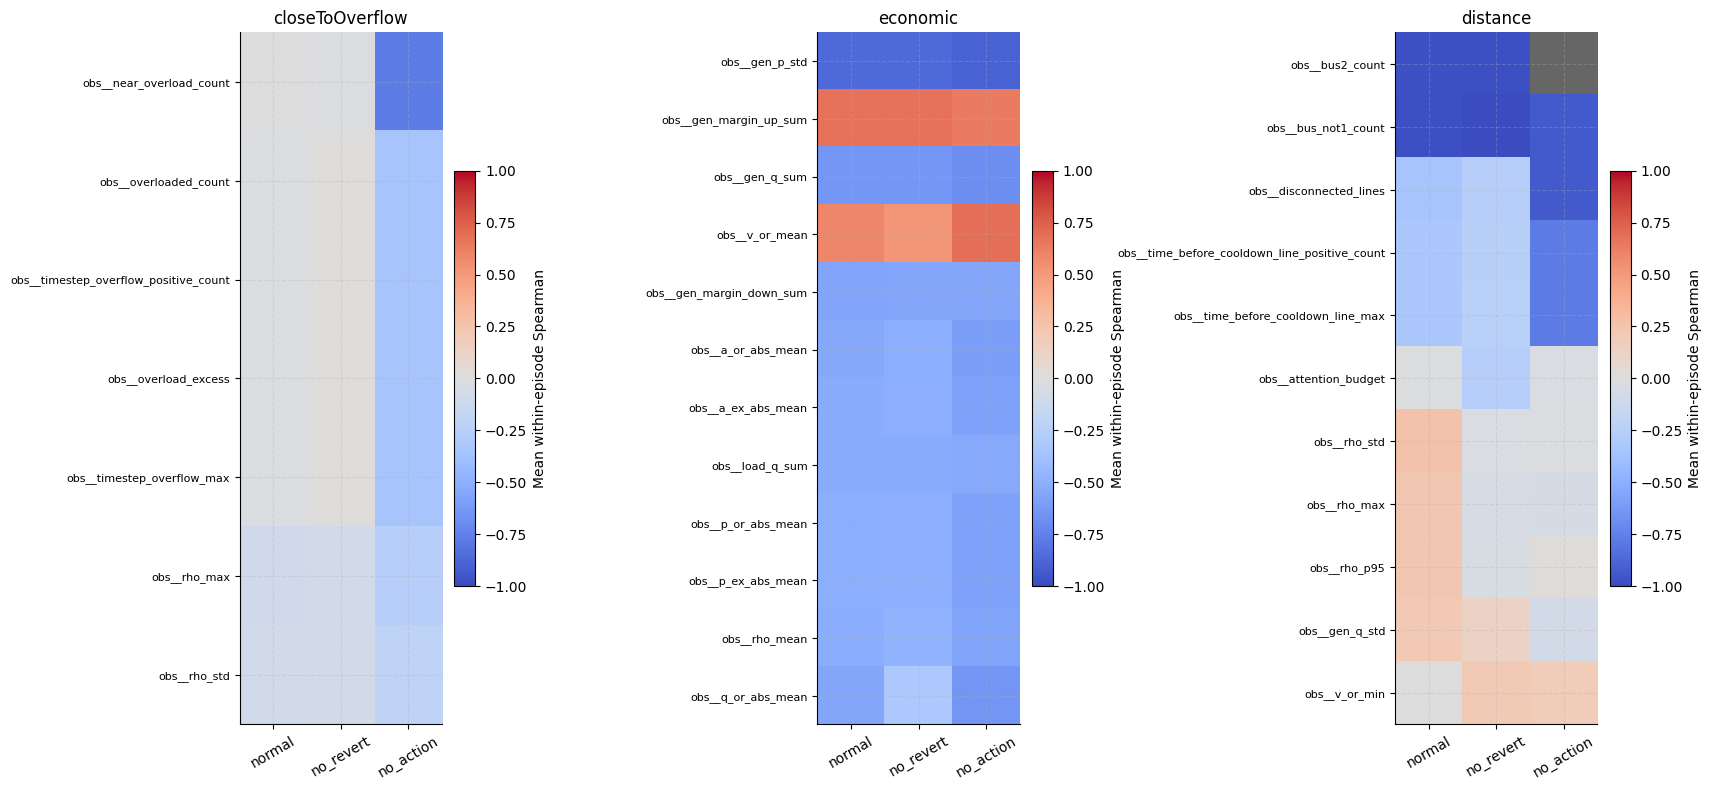

,agent,reward,feature,method,mean_correlation,median_correlation,std_correlation,informative_episodes,total_episodes,sign_agreement,family,eligible,strength
1097,normal,distance,act__bus2_commands,spearman,-0.140216,-0.129475,0.023910,7,7,1.000000,action,False,0.140216
1119,normal,distance,act__intervention,spearman,-0.107887,-0.100698,0.024938,7,7,1.000000,action,False,0.107887
23,no_action,closeToOverflow,act__has_line_switch,spearman,-0.105970,-0.133892,0.054823,7,7,1.000000,action,False,0.105970
31,no_action,closeToOverflow,act__reconnect_count,spearman,-0.105970,-0.133892,0.054823,7,7,1.000000,action,False,0.105970
27,no_action,closeToOverflow,act__intervention,spearman,-0.105970,-0.133892,0.054823,7,7,1.000000,action,False,0.105970
1101,normal,distance,act__bus_commands,spearman,-0.098311,-0.099685,0.014466,7,7,1.000000,action,False,0.098311
1095,normal,distance,act__bus1_commands,spearman,-0.098090,-0.099572,0.014423,7,7,1.000000,action,False,0.098090
1099,normal,distance,act__bus_changes,spearman,-0.098068,-0.099574,0.014484,7,7,1.000000,action,False,0.098068
1117,normal,distance,act__has_topology,spearman,-0.098064,-0.099564,0.014522,7,7,1.000000,action,False,0.098064
1123,normal,distance,act__reconnect_count,spearman,-0.070070,-0.066968,0.037682,3,7,1.000000,action,False,0.070070


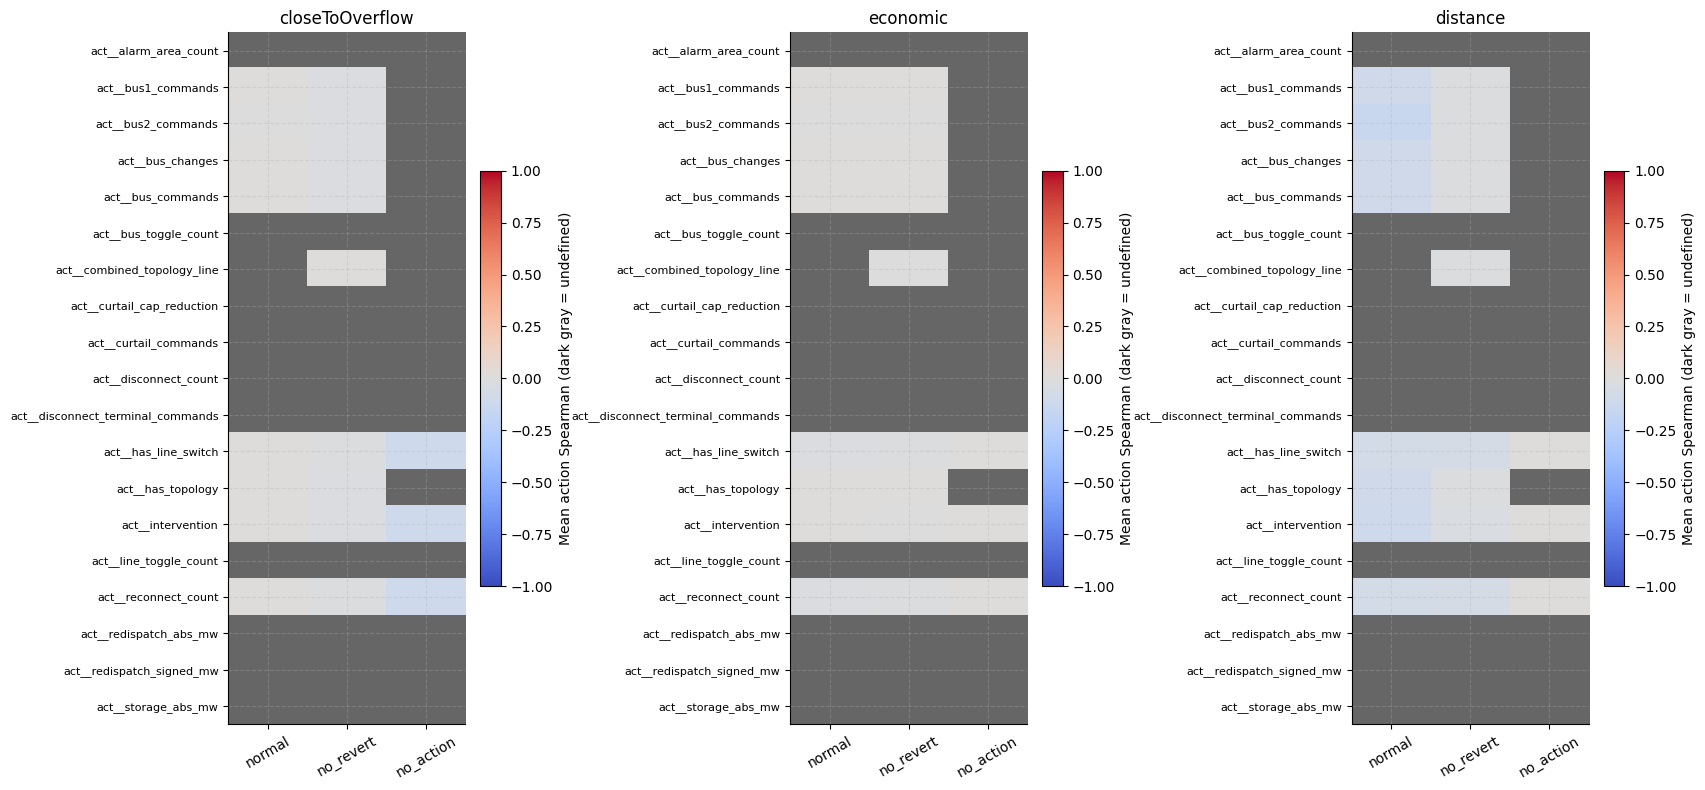

In [7]:
screen = train_summary[train_summary.method == "spearman"].copy()
screen["family"] = np.where(screen.feature.str.startswith("obs__"), "observation", "action")
screen["eligible"] = ((screen.informative_episodes >= MIN_EPISODES) &
                      (screen.mean_correlation.abs() >= MIN_ABS_CORRELATION) &
                      (screen.sign_agreement >= 2/3))
screen["strength"] = screen.mean_correlation.abs()
ranking = (screen[screen.eligible].groupby(["reward", "family", "feature"])
           .agg(training_strength=("strength", "mean"), supporting_agents=("agent", "nunique"))
           .reset_index().sort_values("training_strength", ascending=False))
shortlist = ranking.groupby(["reward", "family"], group_keys=False).head(TOP_N)
validation_view = validation_summary[validation_summary.method == "spearman"]
comparison = screen.merge(validation_view[["agent", "reward", "feature", "mean_correlation", "informative_episodes"]],
    on=["agent", "reward", "feature"], how="left", suffixes=("_train", "_validation"))
display(shortlist)
display(comparison.merge(shortlist[["reward", "feature"]], on=["reward", "feature"])[[
    "agent", "reward", "feature", "mean_correlation_train", "mean_correlation_validation",
    "informative_episodes_train", "informative_episodes_validation", "sign_agreement"]])
shortlist.to_csv(OUTPUT_DIR / "training_shortlist.csv", index=False)
comparison.to_csv(OUTPUT_DIR / "train_validation_comparison.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 8))
for ax, reward in zip(axes, DENSE_REWARDS):
    names = shortlist[shortlist.reward == reward].feature.tolist()
    if not names:
        ax.text(.5, .5, "No eligible features", ha="center", transform=ax.transAxes)
        ax.set_title(reward)
        continue
    matrix = screen[screen.reward == reward].pivot(index="feature", columns="agent", values="mean_correlation").reindex(index=names, columns=AGENTS)
    cmap = plt.get_cmap("coolwarm").copy(); cmap.set_bad("#666666")
    image = ax.imshow(matrix, vmin=-1, vmax=1, cmap=cmap, aspect="auto")
    ax.set(yticks=range(len(names)), yticklabels=names, xticks=range(3), xticklabels=AGENTS, title=reward)
    ax.tick_params(axis="y", labelsize=8)
    ax.tick_params(axis="x", rotation=30)
    fig.colorbar(image, ax=ax, shrink=.6, label="Mean within-episode Spearman")
show_figure(fig, "feature_reward_heatmaps")

# Show action evidence even when no action meets the shortlist threshold.
action_evidence = screen[screen.family == "action"].copy()
action_evidence.to_csv(OUTPUT_DIR / "action_correlation_evidence.csv", index=False)
display(action_evidence.sort_values("strength", ascending=False).head(20))
fig, axes = plt.subplots(1, 3, figsize=(17, 8))
for ax, reward in zip(axes, DENSE_REWARDS):
    matrix = action_evidence[action_evidence.reward == reward].pivot(
        index="feature", columns="agent", values="mean_correlation").reindex(index=action_columns, columns=AGENTS)
    cmap = plt.get_cmap("coolwarm").copy(); cmap.set_bad("#666666")
    image = ax.imshow(matrix, vmin=-1, vmax=1, cmap=cmap, aspect="auto")
    ax.set(yticks=range(len(action_columns)), yticklabels=action_columns,
           xticks=range(3), xticklabels=AGENTS, title=reward)
    ax.tick_params(axis="y", labelsize=8); ax.tick_params(axis="x", rotation=30)
    fig.colorbar(image, ax=ax, shrink=.6, label="Mean action Spearman (dark gray = undefined)")
show_figure(fig, "action_reward_heatmaps")


## 7. Timing and invalid-action sensitivity

Reward formulas generally evaluate the resulting state. Stronger correlations with `post__` than `obs__` help explain this timing, but post-state features cannot be used to choose the same action. Excluding flagged requests shows whether the association is driven by invalid actions. Neither comparison establishes causality.

In [8]:
diagnostic_names = ["rho_max", "near_overload_count", "gen_p_sum", "bus_not1_count"]
post_details = correlations_by_episode(train[train.valid_post], ["post__"+name for name in diagnostic_names])
post_summary = summarize_correlations(post_details)
clean_summary = summarize_correlations(correlations_by_episode(train[~train.flagged], policy_columns))
sensitivity = train_summary.merge(clean_summary, on=["agent", "reward", "feature", "method"],
                                  suffixes=("_all", "_unflagged"))
display(post_summary[post_summary.method == "spearman"])
display(sensitivity[(sensitivity.method == "spearman") & sensitivity.feature.isin(shortlist.feature)][[
    "agent", "reward", "feature", "mean_correlation_all", "mean_correlation_unflagged",
    "informative_episodes_all", "informative_episodes_unflagged"]])
post_summary.to_csv(OUTPUT_DIR / "post_state_diagnostic.csv", index=False)
sensitivity.to_csv(OUTPUT_DIR / "invalid_action_sensitivity.csv", index=False)

,agent,reward,feature,method,mean_correlation,median_correlation,std_correlation,informative_episodes,total_episodes,sign_agreement
1,no_action,closeToOverflow,post__bus_not1_count,spearman,-0.029802,0.010676,8.631675e-02,7,7,0.285714
3,no_action,closeToOverflow,post__gen_p_sum,spearman,0.010024,0.050365,1.273656e-01,7,7,0.714286
5,no_action,closeToOverflow,post__near_overload_count,spearman,-1.000000,-1.000000,9.255561e-10,7,7,1.000000
7,no_action,closeToOverflow,post__rho_max,spearman,-0.270215,-0.277797,4.101479e-02,7,7,1.000000
9,no_action,distance,post__bus_not1_count,spearman,-1.000000,-1.000000,1.110223e-16,7,7,1.000000
11,no_action,distance,post__gen_p_sum,spearman,0.001907,0.067328,1.314953e-01,7,7,0.571429
13,no_action,distance,post__near_overload_count,spearman,-0.029802,0.010676,8.631675e-02,7,7,0.285714
15,no_action,distance,post__rho_max,spearman,-0.045730,-0.031639,4.166998e-02,7,7,1.000000
17,no_action,economic,post__bus_not1_count,spearman,-0.023295,0.005947,8.617390e-02,7,7,0.428571
19,no_action,economic,post__gen_p_sum,spearman,-0.016765,0.083591,3.275584e-01,7,7,0.285714


,agent,reward,feature,mean_correlation_all,mean_correlation_unflagged,informative_episodes_all,informative_episodes_unflagged
41,no_action,closeToOverflow,obs__a_ex_abs_mean,-0.062791,-0.062791,7,7
45,no_action,closeToOverflow,obs__a_or_abs_mean,-0.067137,-0.067137,7,7
49,no_action,closeToOverflow,obs__attention_budget,-0.018053,-0.018053,7,7
51,no_action,closeToOverflow,obs__bus2_count,NaN,NaN,0,0
53,no_action,closeToOverflow,obs__bus_not1_count,-0.047494,-0.047494,7,7
...,...,...,...,...,...,...,...
1383,normal,economic,obs__time_before_cooldown_line_positive_count,-0.088941,-0.088941,3,3
1389,normal,economic,obs__timestep_overflow_max,0.002885,0.002885,5,5
1391,normal,economic,obs__timestep_overflow_positive_count,0.002885,0.002885,5,5
1397,normal,economic,obs__v_or_mean,0.586394,0.586394,7,7


## 8. Investigate one feature instead of trusting the ranking alone

Set `REWARD_TO_INSPECT` and `FEATURE_TO_INSPECT` below. The plot shows training episode averages within feature quantile bins (not all raw, autocorrelated points). Actions with only two values retain those categories. The table shows coverage. Different curves between agents suggest policy/state-distribution confounding.

x         y  episodes  steps
agent     bin                                                
no_action (0.551, 0.624]  0.610333  1.000000         6   4876
          (0.624, 0.644]  0.634522  1.000000         6   5902
          (0.644, 0.663]  0.654141  0.999951         7   6470
          (0.663, 0.693]  0.677471  0.999641         7   5987
          (0.693, 0.734]  0.713691  0.999872         7   5708
          (0.734, 0.781]  0.758349  0.999952         7   5786
          (0.781, 0.84]   0.810106  0.999892         7   6327
          (0.84, 1.885]   0.900086  0.971708         7   8314
no_revert (0.551, 0.624]  0.610171  1.000000         7   8220
          (0.624, 0.644]  0.634911  1.000000         7   7702
          (0.644, 0.663]  0.653180  1.000000         7   6987
          (0.663, 0.693]  0.677279  0.999979         7   7689
          (0.693, 0.734]  0.712724  0.999952         7   8051
          (0.734, 0.781]  0.756508  1.000000         7   7204
          (0.781, 0.84]   0.807568  0.999951         7   5931
          (0.84, 1.885]   0.883984  0.990163         7   4643
normal    (0.551, 0.624]  0.611377  1.000000         7   7182
          (0.624, 0.644]  0.634358  1.000000         7   6675
          (0.644, 0.663]  0.653409  0.999975         7   6820
          (0.663, 0.693]  0.677089  0.999968         7   6602
          (0.693, 0.734]  0.713601  1.000000         7   6520
          (0.734, 0.781]  0.757881  0.999943         7   7287
          (0.781, 0.84]   0.809826  0.999938         7   8020
          (0.84, 1.885]   0.884504  0.994020         7   7321

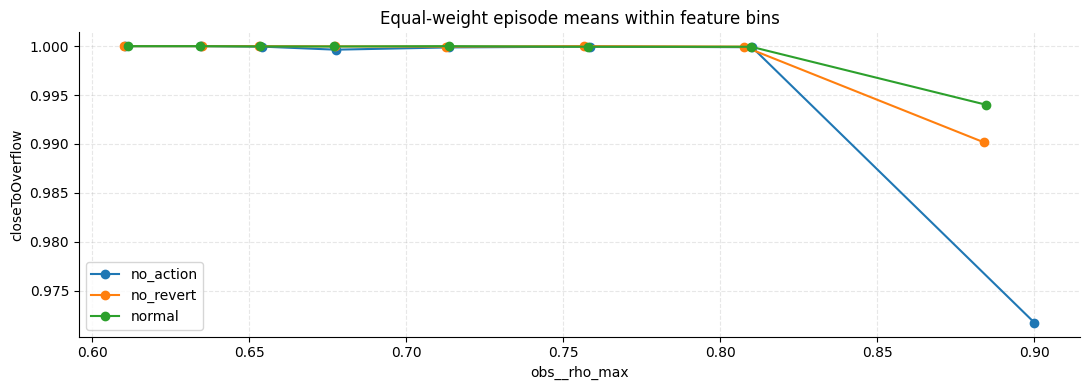

In [9]:
REWARD_TO_INSPECT = "closeToOverflow"
FEATURE_TO_INSPECT = "obs__rho_max"  # try act__intervention or obs__bus_not1_count
if FEATURE_TO_INSPECT not in policy_columns:
    raise ValueError("Choose a feature from observation_columns or action_columns.")
inspect_frame = train[["agent", "episode_id", FEATURE_TO_INSPECT, "reward_"+REWARD_TO_INSPECT]].dropna().copy()
values = inspect_frame[FEATURE_TO_INSPECT]
if values.nunique() <= 8:
    inspect_frame["bin"] = values
else:
    inspect_frame["bin"] = pd.qcut(values, q=8, duplicates="drop")
binned = inspect_frame.groupby(["agent", "episode_id", "bin"], observed=True).agg(
    feature_value=(FEATURE_TO_INSPECT, "mean"), reward_value=("reward_"+REWARD_TO_INSPECT, "mean"), steps=(FEATURE_TO_INSPECT, "size")).reset_index()
binned_summary = binned.groupby(["agent", "bin"], observed=True).agg(
    x=("feature_value", "mean"), y=("reward_value", "mean"), episodes=("episode_id", "nunique"), steps=("steps", "sum"))
display(binned_summary)
fig, ax = plt.subplots()
for agent, group in binned_summary.reset_index().groupby("agent"):
    ax.plot(group.x, group.y, marker="o", label=agent)
ax.set(xlabel=FEATURE_TO_INSPECT, ylabel=REWARD_TO_INSPECT, title="Equal-weight episode means within feature bins")
ax.legend()
show_figure(fig, "inspect_feature")

## 9. AlarmReward: one outcome per episode

For AlarmReward, ordinary step correlations mix thousands of zeros with one terminal value. Instead, compare **last logged reward** with episode summaries: mean/maximum state features and average action counts/rates. These describe trajectory/outcome associations, not instantaneous policy-input features.

Legacy collectors ran until done, but did not save terminal flags. Their last logged rewards are retained and labeled unverified. If all agents have the same terminal reward, correlation is undefined. If an agent has no terminal-reward variation, its within-agent correlations are also undefined. A pooled correlation can simply distinguish policies; do not use it alone to select features.

Episode aggregates include late states and are only for retrospective analysis. For a predictive alarm model, extract a fixed pre-failure history and acquire actual alarm decisions and varying outcomes.

In [23]:
episode_features = features.groupby(episode_keys)[policy_columns].mean().add_suffix("__episode_mean")
last_rows = features.sort_values("t").groupby(episode_keys).tail(1).set_index(episode_keys)
alarm_table = episode_features.join(last_rows[["chronic", "split", "reward_main", "done_recorded", "terminal_flag_available", "episode_length"]])
alarm_table["obs__rho_max__episode_peak"] = features.groupby(episode_keys)["obs__rho_max"].max()
alarm_table[["chronic", "reward_main", "done_recorded", "terminal_flag_available", "episode_length"]]

chronic  reward_main  done_recorded  \
agent     episode_id                                                      
no_action 0             Scenario_august_036          1.0          False   
          1           Scenario_november_067         -1.0          False   
          2              Scenario_march_222          1.0          False   
          3               Scenario_july_055          1.0          False   
          4               Scenario_july_022          1.0          False   
          5            Scenario_october_058         -1.0          False   
          6             Scenario_august_023          1.0          False   
          7                Scenario_may_130          1.0          False   
          8           Scenario_december_157         -1.0          False   
          9             Scenario_august_053          1.0          False   
no_revert 0             Scenario_august_036          1.0          False   
          1           Scenario_november_067          1.0          False   
          2              Scenario_march_222          1.0          False   
          3               Scenario_july_055          1.0          False   
          4               Scenario_july_022          1.0          False   
          5            Scenario_october_058          1.0          False   
          6             Scenario_august_023          1.0          False   
          7                Scenario_may_130          1.0          False   
          8           Scenario_december_157          1.0          False   
          9             Scenario_august_053          1.0          False   
normal    0             Scenario_august_036          1.0          False   
          1           Scenario_november_067          1.0          False   
          2              Scenario_march_222          1.0          False   
          3               Scenario_july_055          1.0          False   
          4               Scenario_july_022          1.0          False   
          5            Scenario_october_058          1.0          False   
          6             Scenario_august_023          1.0          False   
          7                Scenario_may_130          1.0          False   
          8           Scenario_december_157          1.0          False   
          9             Scenario_august_053          1.0          False   

                      terminal_flag_available  episode_length  
agent     episode_id                                           
no_action 0                             False            8062  
          1                             False             141  
          2                             False            8062  
          3                             False            8062  
          4                             False            8062  
          5                             False             153  
          6                             False            8062  
          7                             False            8062  
          8                             False            1005  
          9                             False            8062  
no_revert 0                             False            8062  
          1                             False            8062  
          2                             False            8062  
          3                             False            8062  
          4                             False            8062  
          5                             False            8062  
          6                             False            8062  
          7                             False            8062  
          8                             False            8062  
          9                             False            8062  
normal    0                             False            8062  
          1                             False            8062  
          2                             False            8062  
          3                        

In [21]:
alarm_rows = []
alarm_feature_columns = [c for c in alarm_table if c.startswith(("obs__", "act__"))]

for split in ["train", "validation"]:
    partition = alarm_table[alarm_table.split == split]
    for agent in AGENTS + ["POOLED (confounded)"]:
        group = partition if agent.startswith("POOLED") else partition[partition.index.get_level_values("agent") == agent]
        
        for feature in alarm_feature_columns:
            correlation, n = safe_correlation(group[feature], group.reward_main, minimum=3)
            alarm_rows.append(dict(split=split, agent=agent, feature=feature, correlation=correlation, episodes=n))

alarm_correlations = pd.DataFrame(alarm_rows)
alarm_correlations.sort_values("correlation", key=lambda x: x.abs(), ascending=False).head(25)

,split,agent,feature,correlation,episodes
258,train,POOLED (confounded),obs__hour_sin__episode_mean,-1.000000,21
242,train,POOLED (confounded),obs__attention_budget__episode_mean,1.000000,21
548,validation,no_action,act__reconnect_count__episode_mean,1.000000,3
546,validation,no_action,act__intervention__episode_mean,1.000000,3
544,validation,no_action,act__has_line_switch__episode_mean,1.000000,3
491,validation,no_action,obs__gen_v_mean__episode_mean,1.000000,3
257,train,POOLED (confounded),obs__hour_cos__episode_mean,-1.000000,21
178,train,no_action,obs__hour_cos__episode_mean,-1.000000,7
163,train,no_action,obs__attention_budget__episode_mean,1.000000,7
179,train,no_action,obs__hour_sin__episode_mean,-1.000000,7


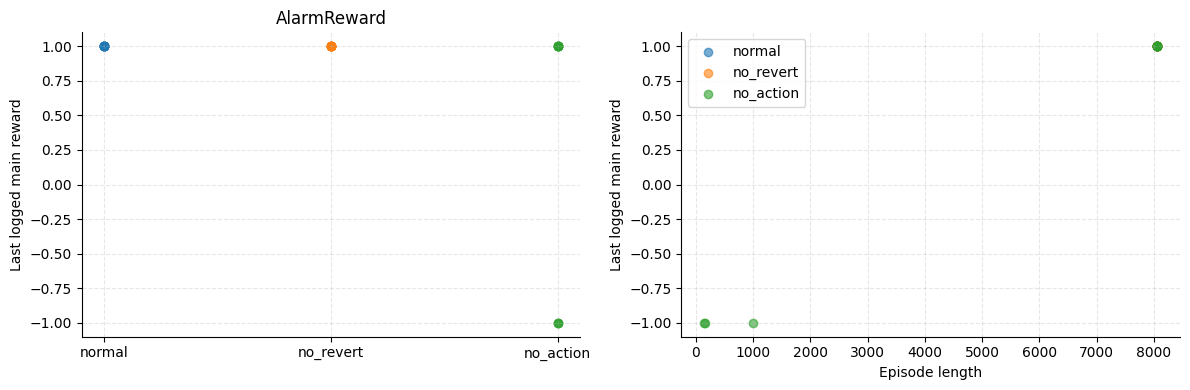

In [22]:
if alarm_correlations[~alarm_correlations.agent.str.startswith("POOLED")].correlation.notna().sum() == 0:
    print("No estimable within-agent alarm correlations: check constant outcomes and episode counts.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i, agent in enumerate(AGENTS):
    group = alarm_table.loc[agent]
    axes[0].scatter(np.full(len(group), i), group.reward_main, alpha=.6)
    axes[1].scatter(group.episode_length, group.reward_main, label=agent, alpha=.6)

axes[0].set(xticks=range(3), xticklabels=AGENTS, ylabel="Last logged main reward", title="AlarmReward" if MAIN_REWARD_IS_ALARM else "Main reward")
axes[1].set(xlabel="Episode length", ylabel="Last logged main reward")
axes[1].legend()

show_figure(fig, "alarm_episode_outcomes")

alarm_table.to_csv(OUTPUT_DIR / "alarm_episode_features.csv")
alarm_correlations.to_csv(OUTPUT_DIR / "alarm_episode_correlations.csv", index=False)

## 10. Remove redundant candidates and export a provisional subset

Keep the training-selected union and remove near-duplicates using |Spearman| > 0.95 **within agent**, requiring at least two informative agents. This pruning is separate for observation and action features. It uses a deterministic sample of at most 10,000 rows per agent for speed; inspect the matrix rather than treating the threshold as a law.

A feature absent from the shortlist may be useful nonlinearly or jointly with other features. Stable correlation can also reflect a reward's definition (e.g. topology distance). The exported subset is a proposal for investigation, not an automatically validated state representation or a causal action ranking. Full episode histories are still needed to model delayed AlarmReward.

**If no action passes the screen, do not remove actions from the MDP or IRL model.** Rare switching commands can have substantial effects despite weak marginal correlation with reward levels. Keep the action representation needed to distinguish decisions (for example bus changes and line reconnections), and use this screen to assess statistical support rather than to redefine the action space. The action heatmaps include all candidates, even those below threshold.


,feature,redundant_with
0,obs__bus_not1_count,obs__bus2_count
1,obs__a_ex_abs_mean,obs__a_or_abs_mean
2,obs__load_q_sum,obs__gen_q_sum
3,obs__p_or_abs_mean,obs__a_or_abs_mean
4,obs__p_ex_abs_mean,obs__a_or_abs_mean
5,obs__rho_mean,obs__a_or_abs_mean
6,obs__time_before_cooldown_line_max,obs__time_before_cooldown_line_positive_count
7,obs__timestep_overflow_positive_count,obs__overloaded_count
8,obs__overload_excess,obs__overloaded_count
9,obs__timestep_overflow_max,obs__overloaded_count


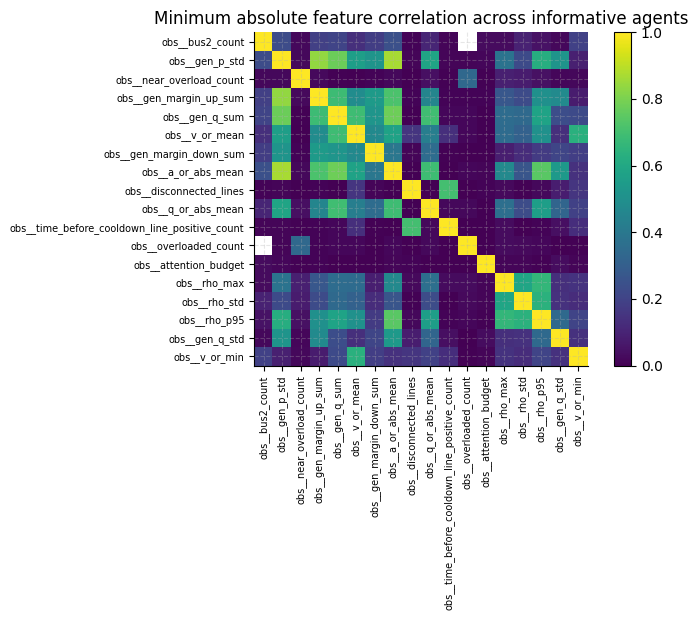

{'observations': ['obs__bus2_count',
  'obs__gen_p_std',
  'obs__near_overload_count',
  'obs__gen_margin_up_sum',
  'obs__gen_q_sum',
  'obs__v_or_mean',
  'obs__gen_margin_down_sum',
  'obs__a_or_abs_mean',
  'obs__disconnected_lines',
  'obs__q_or_abs_mean',
  'obs__time_before_cooldown_line_positive_count',
  'obs__overloaded_count',
  'obs__attention_budget',
  'obs__rho_max',
  'obs__rho_std',
  'obs__rho_p95',
  'obs__gen_q_std',
  'obs__v_or_min'],
 'actions': [],
 'train_chronics': [np.str_('Scenario_august_023'),
  np.str_('Scenario_august_053'),
  np.str_('Scenario_december_157'),
  np.str_('Scenario_july_022'),
  np.str_('Scenario_july_055'),
  np.str_('Scenario_march_222'),
  np.str_('Scenario_may_130')],
 'validation_chronics': [np.str_('Scenario_august_036'),
  np.str_('Scenario_november_067'),
  np.str_('Scenario_october_058')],
 'method': 'Training within-episode Spearman screening; descriptive, not causal',
 'main_reward_assumed_alarm': True}

Tables, figures, cache and provisional subset saved in /Users/dave/Library/CloudStorage/GoogleDrive-davidesalaorni@gmail.com/Il mio Drive/Projects/ai4realnet/greedy-agent/artifacts/reward_correlations


In [11]:
candidate_order = (shortlist.sort_values("training_strength", ascending=False).feature.drop_duplicates().tolist())
if candidate_order:
    redundancy_matrices = []
    for agent, group in train.groupby("agent"):
        sample = group[candidate_order].sample(min(10000, len(group)), random_state=SPLIT_SEED)
        # Rank then Pearson avoids requiring scipy for Spearman.
        redundancy_matrices.append(sample.rank().corr().abs())
    stacked = np.stack([m.to_numpy() for m in redundancy_matrices])
    support = np.isfinite(stacked).sum(axis=0)
    
    # Conservative: all informative agents must show high redundancy.
    minimum = np.where(np.isfinite(stacked), stacked, np.inf).min(axis=0)
    redundancy = pd.DataFrame(np.where(support >= 2, minimum, np.nan), index=candidate_order, columns=candidate_order)
    
    selected, removed = [], []
    for feature in candidate_order:
        duplicate = next((kept for kept in selected if kept.split("__")[0] == feature.split("__")[0]
                          and redundancy.loc[feature, kept] > .95), None)
        if duplicate:
            removed.append(dict(feature=feature, redundant_with=duplicate))
        else:
            selected.append(feature)
    display(pd.DataFrame(removed))
    
    fig, ax = plt.subplots(figsize=(max(8, len(selected)*.35), max(6, len(selected)*.35)))
    image = ax.imshow(redundancy.loc[selected, selected], vmin=0, vmax=1, cmap="viridis")
    ax.set(xticks=range(len(selected)), xticklabels=selected, yticks=range(len(selected)), yticklabels=selected,
           title="Minimum absolute feature correlation across informative agents")
    ax.tick_params(axis="x", rotation=90, labelsize=7); ax.tick_params(axis="y", labelsize=7)
    fig.colorbar(image, ax=ax)
    show_figure(fig, "selected_feature_redundancy")
    redundancy.to_csv(OUTPUT_DIR / "candidate_redundancy.csv")
else:
    selected = []
    print("No features meet the training rules; inspect variation and support before relaxing thresholds.")

selection = dict(observations=[c for c in selected if c.startswith("obs__")],
                 actions=[c for c in selected if c.startswith("act__")],
                 train_chronics=sorted(train_chronics), validation_chronics=sorted(set(chronics)-train_chronics),
                 method="Training within-episode Spearman screening; descriptive, not causal",
                 main_reward_assumed_alarm=MAIN_REWARD_IS_ALARM)

(OUTPUT_DIR / "provisional_feature_subset.json").write_text(json.dumps(selection, indent=2))
display(selection)
print("Tables, figures, cache and provisional subset saved in", OUTPUT_DIR)